In [1]:
import pandas as pd
import torch
import numpy as np
import random
import os

import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import matplotlib.pyplot as plt

In [2]:
train_df = pd.read_csv("../data/burgers_train.csv")
test_df = pd.read_csv("../data/burgers_test.csv")

In [3]:
def prepare_deeponet_data(df, Nx=32, Nt=500):
    """Formats wide DataFrames into structured arrays for DeepONet training."""
    num_samples = len(df)
    total_mesh = Nx * Nt
    vals = df.values

    # Extract raw vectors from dataframe
    x_flat = vals[:, 3 : 3 + total_mesh]
    t_flat = vals[:, 3 + total_mesh : 3 + 2 * total_mesh]
    u_flat = vals[:, 3 + 2 * total_mesh :]

    # Reshape matrices
    x_mesh = x_flat.reshape(num_samples, Nt, Nx)
    t_mesh = t_flat.reshape(num_samples, Nt, Nx)
    u_mesh = u_flat.reshape(num_samples, Nt, Nx)

    # Branch Input: Initial Condition u(x, t=0) -> Shape: [Samples, Nx]
    u_init = torch.tensor(u_mesh[:, 0, :], dtype=torch.float32)

    # Trunk Input: (x, t) coordinate pairs
    x_coords = torch.tensor(x_mesh[0].flatten(), dtype=torch.float32)
    t_coords = torch.tensor(t_mesh[0].flatten(), dtype=torch.float32)
    coords = torch.stack([x_coords, t_coords], dim=-1)  # Shape: [Nx * Nt, 2]

    targets = torch.tensor(u_mesh.reshape(num_samples, -1), dtype=torch.float32)

    return TensorDataset(u_init, targets), coords

train_dataset, coords = prepare_deeponet_data(train_df, Nx=32, Nt=500)
test_dataset, _ = prepare_deeponet_data(test_df, Nx=32, Nt=500)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [4]:
class BranchNet(nn.Module):
    """Classic DeepONet branch network that processes the initial condition profile."""
    def __init__(self, input_dim=32, hidden_dim=128, output_dim=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.network(x)


class TrunkNet(nn.Module):
    """MLP to process continuous space-time coordinate queries."""
    def __init__(self, in_dim=2, hidden_dim=64, layers=3, output_dim=64):
        super().__init__()
        net = []
        current_dim = in_dim
        for _ in range(layers):
            net.append(nn.Linear(current_dim, hidden_dim))
            net.append(nn.Tanh())
            current_dim = hidden_dim
        net.append(nn.Linear(current_dim, output_dim))
        self.mlp = nn.Sequential(*net)

    def forward(self, x):
        return self.mlp(x)


class DeepONet(nn.Module):
    """Classic DeepONet architecture using a dot product between branch and trunk outputs."""
    def __init__(self, branch_net, trunk_net):
        super().__init__()
        self.branch = branch_net
        self.trunk = trunk_net

    def forward(self, x_branch, x_trunk):
        # x_branch: [Batch, Nx] -> Embedding: [Batch, output_dim]
        b_emb = self.branch(x_branch)
        # x_trunk: [Nx * Nt, 2] -> Embedding: [Nx * Nt, output_dim]
        t_emb = self.trunk(x_trunk)

        # [Batch, output_dim] x [output_dim, Nx * Nt] -> [Batch, Nx * Nt]
        out = torch.matmul(b_emb, t_emb.T)
        return out


class RelativeL2Loss(object):
    def __call__(self, y_pred, y_true):
        num_examples = y_pred.size(0)
        diff_norms = torch.norm(y_pred.reshape(num_examples, -1) - y_true.reshape(num_examples, -1), 2, 1)
        true_norms = torch.norm(y_true.reshape(num_examples, -1), 2, 1)
        return torch.mean(diff_norms / (true_norms + 1e-8))

In [5]:
def sample_hyperparameters(space):
    return {k: random.choice(v) for k, v in space.items()}

def train_and_evaluate_don(config, train_loader, test_loader, coords, epochs=10):
    branch = BranchNet(input_dim=32, hidden_dim=config["branch_hidden"], output_dim=config["embedding_dim"])
    trunk = TrunkNet(in_dim=2, hidden_dim=config["trunk_hidden"], layers=config["trunk_layers"], output_dim=config["embedding_dim"])
    model = DeepONet(branch, trunk)

    optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = RelativeL2Loss()

    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()
        for X_branch, Y_target in train_loader:
            optimizer.zero_grad()
            output = model(X_branch, coords)
            loss = criterion(output, Y_target)
            loss.backward()
            optimizer.step()
        scheduler.step()

        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_branch, Y_target in test_loader:
                output = model(X_branch, coords)
                val_loss += criterion(output, Y_target).item() * X_branch.size(0)

        val_loss /= len(test_loader.dataset)
        if val_loss < best_val_loss:
            best_val_loss = val_loss

    return best_val_loss

In [ ]:
PARAM_SPACE_DON = {
    "branch_hidden": [64, 128, 256],
    "trunk_hidden": [32, 64, 128],
    "trunk_layers": [2, 3, 4],
    "embedding_dim": [32, 64, 96],
    "lr": [1e-3, 2e-3, 5e-3],
    "weight_decay": [1e-6, 1e-4, 0.0],
}

NUM_SEARCH_ITERATIONS = 10
EPOCHS_PER_RUN = 10

best_don_loss = float("inf")
best_don_config = None

print("Starting DeepONet Random Search on CPU...")

for trial in range(NUM_SEARCH_ITERATIONS):
    current_config = sample_hyperparameters(PARAM_SPACE_DON)
    print(f"\n--- Trial {trial + 1}/{NUM_SEARCH_ITERATIONS} ---")
    print(f"Testing Config: {current_config}")

    score = train_and_evaluate_don(current_config, train_loader, test_loader, coords, epochs=EPOCHS_PER_RUN)
    print(f"Trial Best Val Relative L2 Loss: {score:.5f}")

    if score < best_don_loss:
        best_don_loss = score
        best_don_config = current_config
        print(" New overall best DeepONet configuration discovered!")

Starting DeepONet Random Search on CPU...

--- Trial 1/10 ---
Testing Config: {'branch_hidden': 256, 'trunk_hidden': 32, 'trunk_layers': 2, 'embedding_dim': 96, 'lr': 0.005, 'weight_decay': 0.0001}
Trial Best Val Relative L2 Loss: 0.37089
 New overall best DeepONet configuration discovered!

--- Trial 2/10 ---
Testing Config: {'branch_hidden': 256, 'trunk_hidden': 128, 'trunk_layers': 2, 'embedding_dim': 96, 'lr': 0.005, 'weight_decay': 0.0}
Trial Best Val Relative L2 Loss: 0.16167
 New overall best DeepONet configuration discovered!

--- Trial 3/10 ---
Testing Config: {'branch_hidden': 64, 'trunk_hidden': 32, 'trunk_layers': 4, 'embedding_dim': 32, 'lr': 0.001, 'weight_decay': 0.0}
Trial Best Val Relative L2 Loss: 0.41190

--- Trial 4/10 ---
Testing Config: {'branch_hidden': 64, 'trunk_hidden': 32, 'trunk_layers': 4, 'embedding_dim': 64, 'lr': 0.001, 'weight_decay': 0.0}
Trial Best Val Relative L2 Loss: 0.41476

--- Trial 5/10 ---
Testing Config: {'branch_hidden': 64, 'trunk_hidden': 

In [ ]:
print("\n================ RETRAINING BEST DEEPONET ================")
print(f"Using Configuration: {best_don_config}")

final_branch = BranchNet(input_dim=32, hidden_dim=best_don_config["branch_hidden"], output_dim=best_don_config["embedding_dim"])
final_trunk = TrunkNet(in_dim=2, hidden_dim=best_don_config["trunk_hidden"], layers=best_don_config["trunk_layers"], output_dim=best_don_config["embedding_dim"],)
final_don_model = DeepONet(final_branch, final_trunk)

optimizer = torch.optim.AdamW(final_don_model.parameters(), lr=best_don_config["lr"], weight_decay=best_don_config["weight_decay"],)
FINAL_EPOCHS = 100

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINAL_EPOCHS)
criterion = RelativeL2Loss()

train_loss_history = []
val_loss_history = []

for epoch in range(1, FINAL_EPOCHS + 1):
    final_don_model.train()
    running_train_loss = 0.0

    for X_branch, Y_target in train_loader:
        optimizer.zero_grad()
        output = final_don_model(X_branch, coords)
        loss = criterion(output, Y_target)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * X_branch.size(0)

    scheduler.step()
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_loss_history.append(epoch_train_loss)

    # Validation
    final_don_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for X_branch, Y_target in test_loader:
            output = final_don_model(X_branch, coords)
            running_val_loss += criterion(output, Y_target).item() * X_branch.size(0)

    epoch_val_loss = running_val_loss / len(test_loader.dataset)
    val_loss_history.append(epoch_val_loss)

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch [{epoch:3d}/{FINAL_EPOCHS}] | Train Loss: {epoch_train_loss:.5f} | Val Loss: {epoch_val_loss:.5f}")

# Save DeepONet weights
torch.save(final_don_model.state_dict(), "../best_models/best_classic_deeponet_burgers.pt")
print("\nClassic DeepONet retraining completed and saved successfully!")


================ RETRAINING BEST DEEPONET ================
Using Configuration: {'branch_hidden': 256, 'trunk_hidden': 128, 'trunk_layers': 2, 'embedding_dim': 96, 'lr': 0.005, 'weight_decay': 0.0}
Epoch [  1/100] | Train Loss: 3.63651 | Val Loss: 0.50463
Epoch [ 10/100] | Train Loss: 0.19404 | Val Loss: 0.25141
Epoch [ 20/100] | Train Loss: 0.09928 | Val Loss: 0.13202
Epoch [ 30/100] | Train Loss: 0.09297 | Val Loss: 0.09586
Epoch [ 40/100] | Train Loss: 0.09619 | Val Loss: 0.08264
Epoch [ 50/100] | Train Loss: 0.08091 | Val Loss: 0.07345
Epoch [ 60/100] | Train Loss: 0.07381 | Val Loss: 0.07262
Epoch [ 70/100] | Train Loss: 0.06664 | Val Loss: 0.06654
Epoch [ 80/100] | Train Loss: 0.06581 | Val Loss: 0.06305
Epoch [ 90/100] | Train Loss: 0.06030 | Val Loss: 0.06012
Epoch [100/100] | Train Loss: 0.05953 | Val Loss: 0.05937

Classic DeepONet retraining completed and saved successfully!


In [13]:
# Load the best model for evaluation and visualization
best_don_config = {'branch_hidden': 256, 'trunk_hidden': 128, 'trunk_layers': 2, 'embedding_dim': 96, 'lr': 0.005, 'weight_decay': 0.0}
final_branch = BranchNet(input_dim=32, hidden_dim=best_don_config["branch_hidden"], output_dim=best_don_config["embedding_dim"])
final_trunk = TrunkNet(in_dim=2, hidden_dim=best_don_config["trunk_hidden"], layers=best_don_config["trunk_layers"], output_dim=best_don_config["embedding_dim"],)
final_don_model = DeepONet(final_branch, final_trunk)

FINAL_EPOCHS = 100
final_don_model.load_state_dict(torch.load("../Models/best_models/best_classic_deeponet_burgers.pt", weights_only=True))
final_don_model.eval()

DeepONet(
  (branch): BranchNet(
    (network): Sequential(
      (0): Linear(in_features=32, out_features=256, bias=True)
      (1): Tanh()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): Tanh()
      (4): Linear(in_features=256, out_features=96, bias=True)
    )
  )
  (trunk): TrunkNet(
    (mlp): Sequential(
      (0): Linear(in_features=2, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
      (4): Linear(in_features=128, out_features=96, bias=True)
    )
  )
)

In [17]:
output_dir = "../Plots/deeponet_burgers_plots"
os.makedirs(output_dir, exist_ok=True)

final_don_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_branch, Y_target in test_loader:
        output = final_don_model(X_branch, coords)
        all_preds.append(output.numpy())
        all_targets.append(Y_target.numpy())

all_preds = np.concatenate(all_preds, axis=0)  # Shape: (N_test, 16000)
all_targets = np.concatenate(all_targets, axis=0)  # Shape: (N_test, 16000)

# Reshape arrays back into 2D space-time topologies
Nx, Nt = 32, 500
all_preds_mesh = all_preds.reshape(-1, Nt, Nx)
all_targets_mesh = all_targets.reshape(-1, Nt, Nx)
abs_error_mesh = np.abs(all_targets_mesh - all_preds_mesh)

# Reconstruct 1D plotting coordinates
x_axis = coords[:Nx, 0].numpy()
time_axis = coords[::Nx, 1].numpy()

In [14]:
# --- Plot 1: Learning Curve ---
plt.figure(figsize=(7, 4.5))
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    train_loss_history,
    label="Train Loss",
    color="blue",
)
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    val_loss_history,
    label="Val Loss",
    color="red",
    linestyle="--",
)
plt.xlabel("Epochs")
plt.ylabel("Relative L2 Loss")
plt.title("Krzywa uczenia DeepONet Burgers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_history_DeepONet.png"), dpi=300)
plt.show()

NameError: name 'train_loss_history' is not defined

<Figure size 700x450 with 0 Axes>

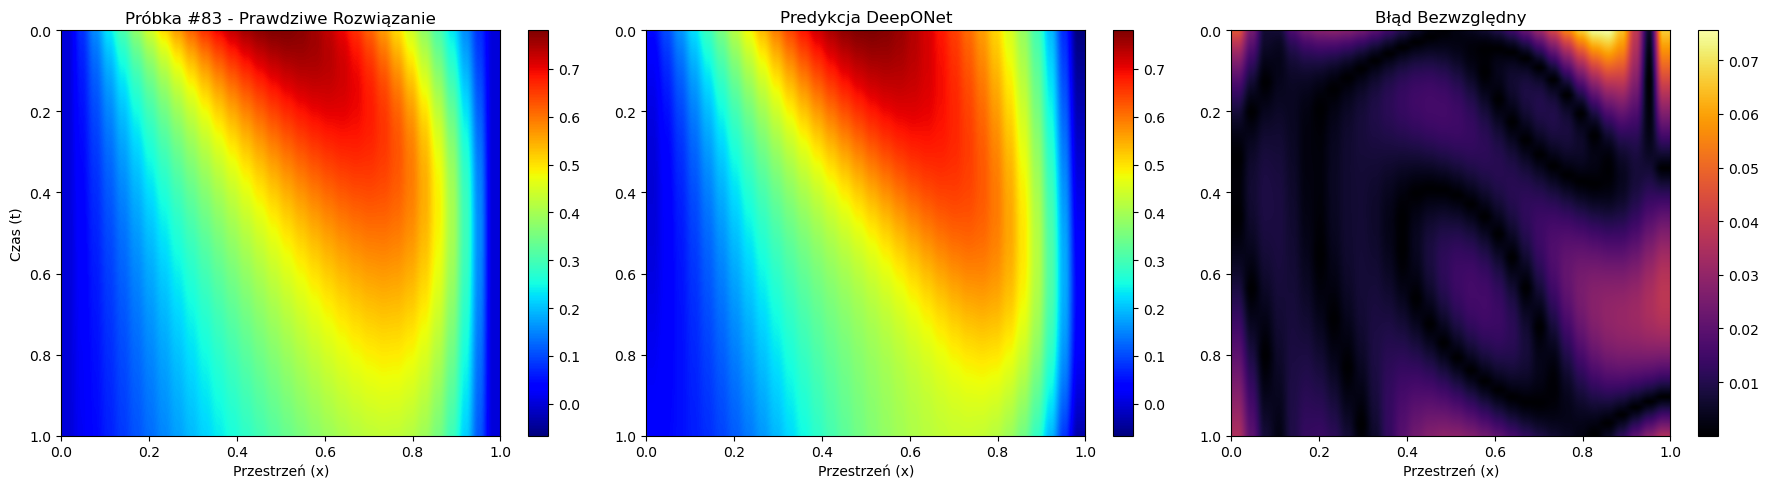

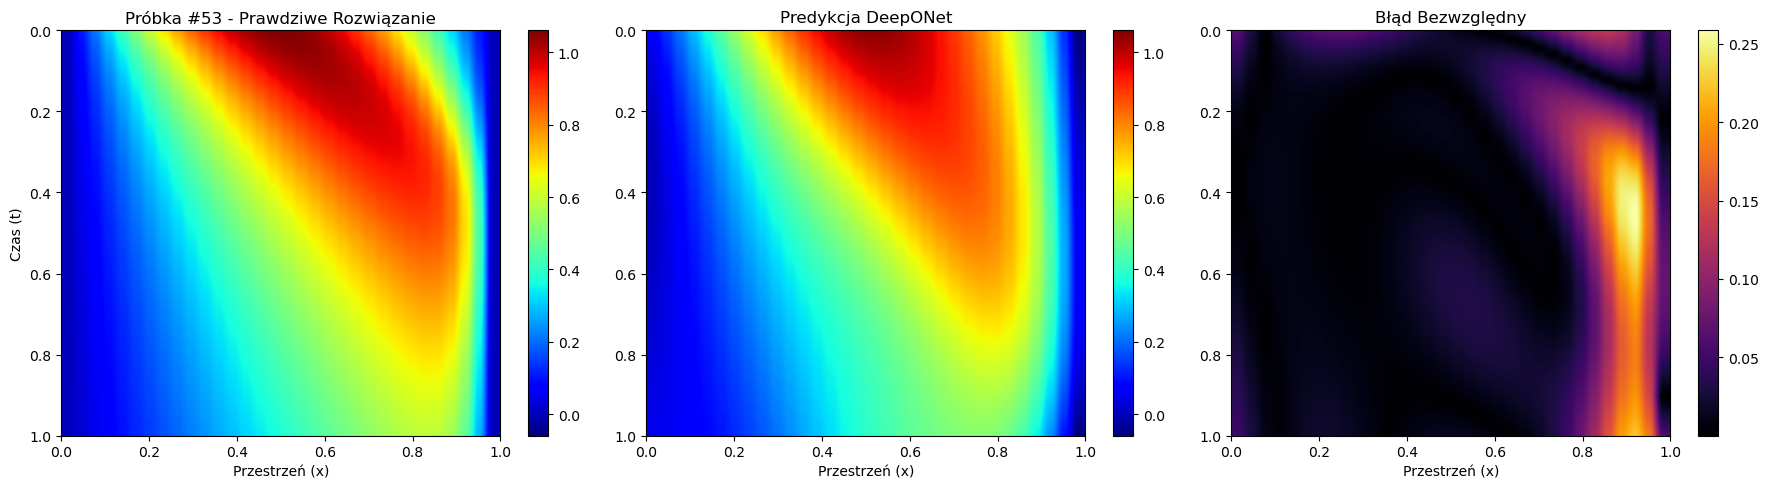

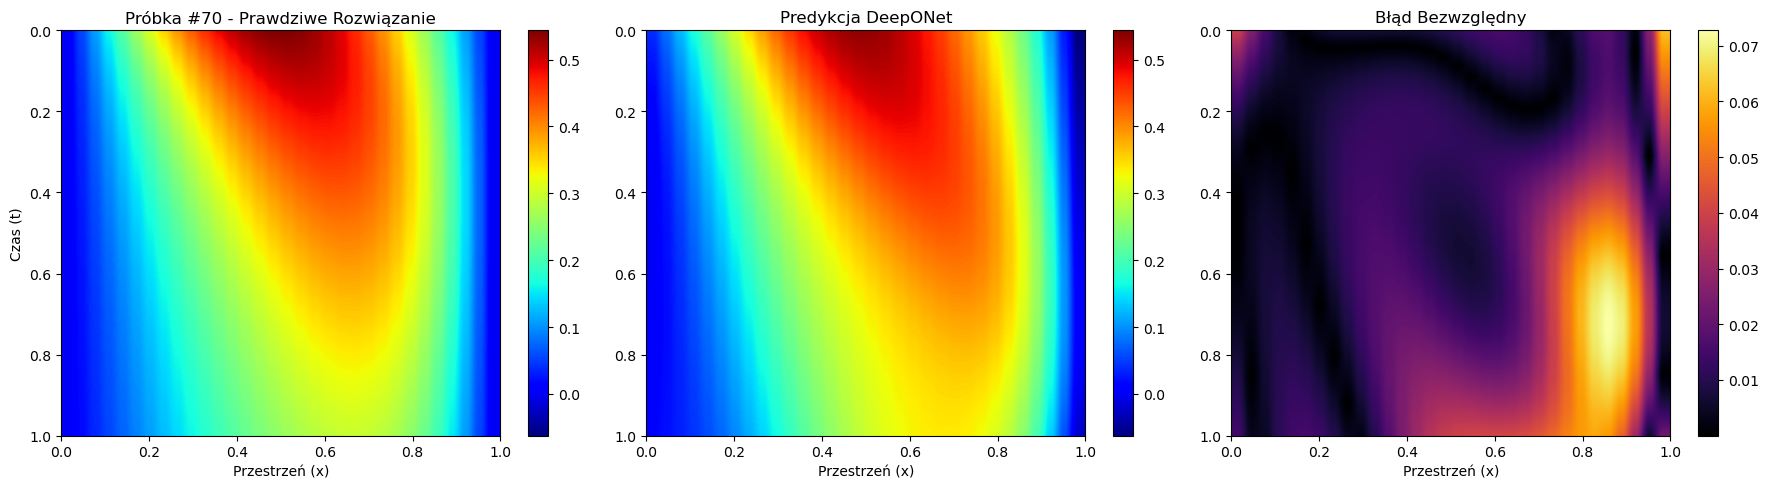

In [18]:
# --- Plot 2: Random Target Sample Contour Matrices ---
np.random.seed(42)
random_indices = np.random.choice(len(all_preds_mesh), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    vmin = min(
        all_targets_mesh[sample_idx].min(), all_preds_mesh[sample_idx].min()
    )
    vmax = max(
        all_targets_mesh[sample_idx].max(), all_preds_mesh[sample_idx].max()
    )

    im0 = axes[0].imshow(
        all_targets_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title(f"Próbka #{sample_idx} - Prawdziwe Rozwiązanie")
    axes[0].set_ylabel("Czas (t)")
    axes[0].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(
        all_preds_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[1].set_title("Predykcja DeepONet")
    axes[1].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(
        abs_error_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="inferno",
    )
    axes[2].set_title("Błąd Bezwzględny")
    axes[2].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im2, ax=axes[2])

    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f"sample_{sample_idx}_deeponet_analysis.png"),
        dpi=300,
    )
    plt.show()

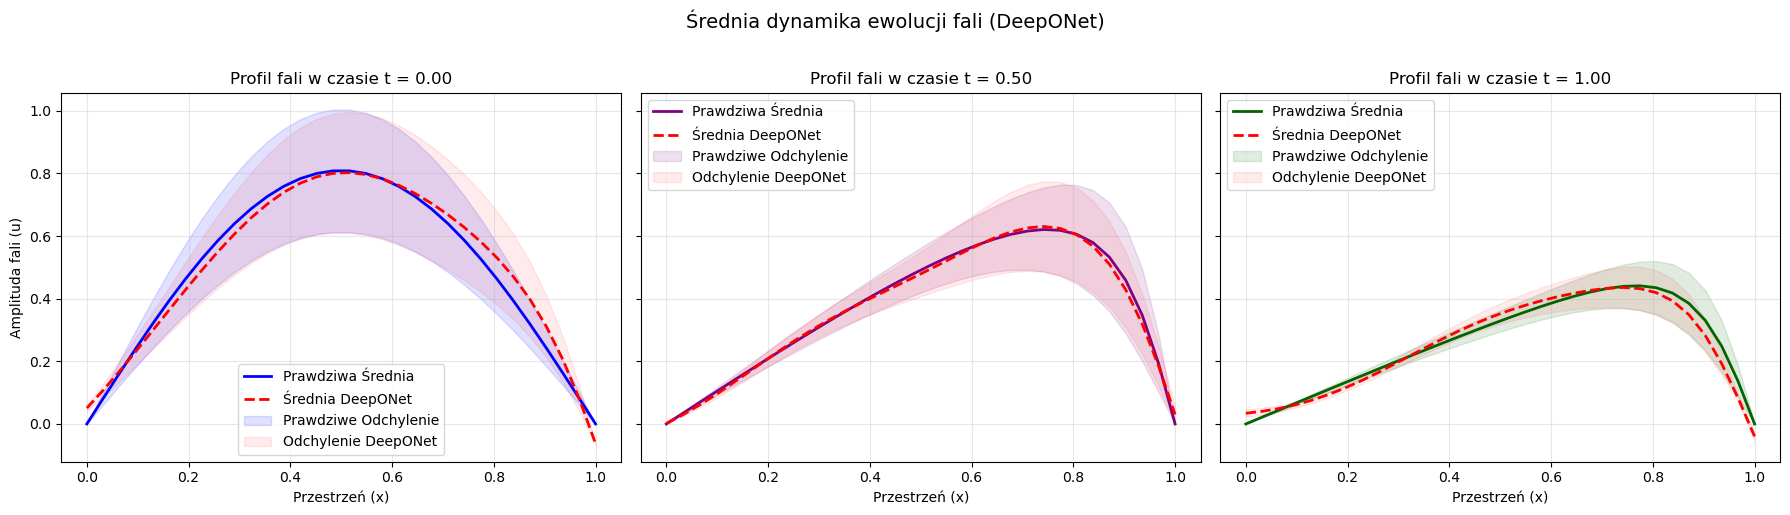

In [22]:
# Compute means and standard deviations across all validation profiles
# Shape of arrays: [Samples, Nt, Nx]
mean_target = all_targets_mesh.mean(axis=0)  # Shape: [Nt, Nx]
mean_pred = all_preds_mesh.mean(axis=0)  # Shape: [Nt, Nx]
std_target = all_targets_mesh.std(axis=0)  # Shape: [Nt, Nx]
std_pred = all_preds_mesh.std(axis=0)  # Shape: [Nt, Nx]

# Pick temporal indexes to review (Initial wave form, midpoint, final dissipation state)
time_slices = [0, len(time_axis) // 2, -1]
slice_colors = ["blue", "purple", "darkgreen"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for idx, t_idx in enumerate(time_slices):
    actual_t = time_axis[t_idx]

    # Ground truth mean profile
    axes[idx].plot(
        x_axis,
        mean_target[t_idx],
        color=slice_colors[idx],
        linewidth=2,
        label="Prawdziwa Średnia",
    )

    # DeepONet mean profile prediction
    axes[idx].plot(
        x_axis,
        mean_pred[t_idx],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Średnia DeepONet",
    )

    # Fill boundaries showing physical deviation distribution across the dataset
    axes[idx].fill_between(
        x_axis,
        mean_target[t_idx] - std_target[t_idx],
        mean_target[t_idx] + std_target[t_idx],
        color=slice_colors[idx],
        alpha=0.12,
        label="Prawdziwe Odchylenie",
    )

    # NOWY ELEMENT: Cieniowanie odchylenia standardowego dla przewidywań modelu DeepONet
    axes[idx].fill_between(
        x_axis,
        mean_pred[t_idx] - std_pred[t_idx],
        mean_pred[t_idx] + std_pred[t_idx],
        color="red",
        alpha=0.08,  # Niższa przezroczystość zapobiega nakładaniu się kolorów w nieczytelny sposób
        label="Odchylenie DeepONet",
    )

    axes[idx].set_title(f"Profil fali w czasie t = {actual_t:.2f}")
    axes[idx].set_xlabel("Przestrzeń (x)")

    if idx == 0:
        axes[idx].set_ylabel("Amplituda fali (u)")
        axes[idx].legend(loc="lower center")
    elif idx == 1:
        axes[idx].legend(loc="upper left")
    else:
        axes[idx].legend(loc="upper left")
    axes[idx].grid(True, alpha=0.3)

plt.suptitle(
    "Średnia dynamika ewolucji fali (DeepONet)", fontsize=14, y=1.02
)
plt.tight_layout()

# Save the statistics profile analysis sheet
plot3_path = os.path.join(output_dir, "Burgers_DeepONet_averages.png")
plt.savefig(plot3_path, dpi=300, bbox_inches="tight")
plt.show()